# A curved sea floor in 3-D

`PropSEM(interfaces=...)` builds a Hex27 mesh whose element layers follow curved internal
interfaces, as SPECFEM3D's internal mesher follows those of its `interfaces.dat`, and
`layered_model` gives each layer its material. A sea floor is the case where this is needed:
`BiotVSSEM3DDeformed` models water (`biot_fluid`) and a dry rock (`biot_elastic`) in one
mesh, coupled across their faces as SPECFEM3D couples its acoustic and elastic domains, but
each element has to be wholly one medium. With the mesh following the sea floor, the fluid-solid
faces are the sea floor itself.

1. The mesh: element layers following a seamount.
2. An air gun over the seamount: the pressure in the water and the particle velocity on the sea
   floor, against a flat sea floor.

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations.biot_params import biot_elastic, biot_fluid
from sweep.propagator import EagerOptions, Full
from sweep.sem import BiotVSSEM3DDeformed, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"   # fp64 here, so eager (impl='c' is fp32)
F64 = torch.float64
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print(f"device {DEV}")

device cuda


## 1. The mesh

A 600 m by 400 m area, 400 m deep, on 10 m grid steps (40 m elements at `n_order = 4`). The sea
floor lies 120 m deep and rises to 50 m over a seamount; the water gets three element layers and
the rock seven. The interfaces are given like `topography`, in rows of the model grid, one
`(ny, nx)` array each.

In [2]:
DH, NO, F0, DELAY = 10.0, 4, 15.0, 0.08
SHAPE, ABCN, DT, NT = (41, 41, 61), 16, 5e-4, 1200          # (nz, ny, nx), 0.6 s
ny, nx = SHAPE[1:]
yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing="ij")
seamount = 12.0 - 7.0 * np.exp(-((xx - 30.0) ** 2 + (yy - 20.0) ** 2) / (2 * 6.0 ** 2))
flat = np.full((ny, nx), 12.0)
WATER = biot_fluid(1020.0 * 1500.0 ** 2, 1020.0)
ROCK = biot_elastic(2400.0, 1300.0, 2000.0)


def solver(floor):
    return PropSEM(BiotVSSEM3DDeformed, shape=SHAPE, dh=DH, dt=DT, n_order=NO, abcn=ABCN,
                   free_surface=True, interfaces=[floor], interface_elements=[3, 7],
                   f_dominant=F0, dev=DEV, dtype=F64, impl="eager", memory=Full(),
                   eager_options=EagerOptions(use_compile=False), source_type=["p"],
                   receiver_type=["vx", "vy", "vz", "p"])


p_sea, p_flat = solver(seamount), solver(flat)
mesh = p_sea.mesh
print(f"{mesh.n_elements} elements, {p_sea._build_eq([p_sea.layered_model(c) for c in zip(WATER, ROCK)]).ifc.n_face} fluid-solid faces")

5796 elements, 414 fluid-solid faces


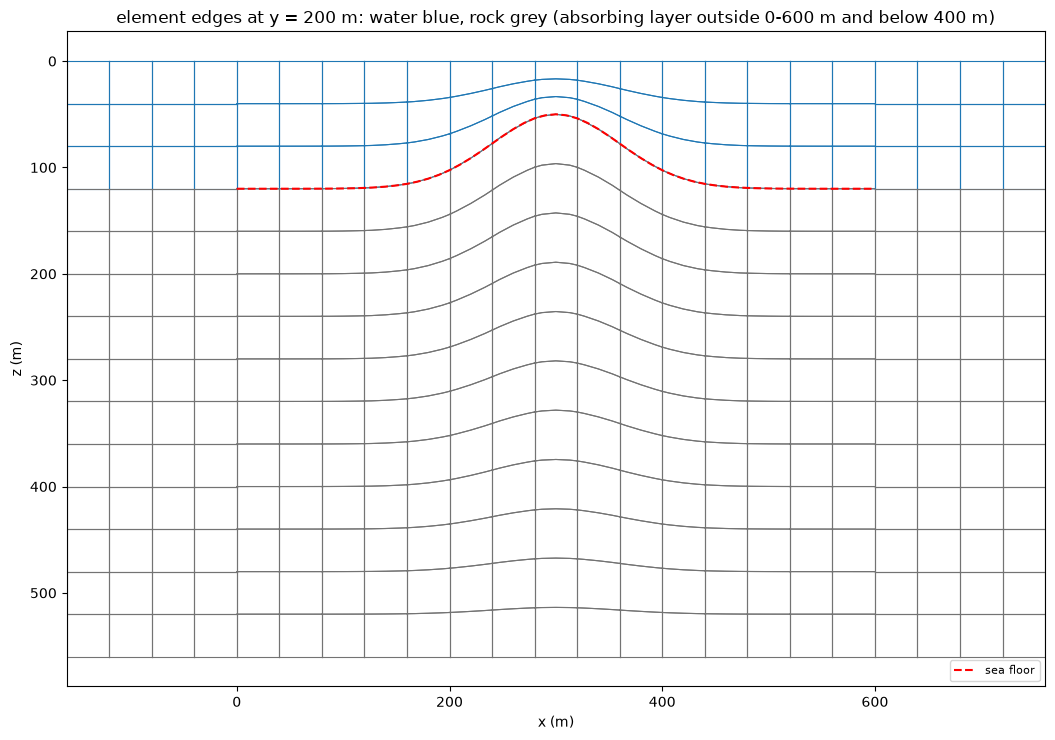

In [3]:
# the element edges on the vertical plane through the seamount (y = 200 m): the GLL nodes of
# the elements cut by it, joined along x and along z
pz, py, px = p_sea._pad0
y0 = (20.0 + py) * DH
ye = mesh.y_e.cpu().numpy()
sel = np.where(np.abs(ye[:, 0, 0, 0] - y0) < 1e-6)[0]              # elements starting at y0
xe, ze = mesh.x_e.cpu().numpy(), mesh.z_e.cpu().numpy()
k = 0                                                               # their face at y0
fig, ax = plt.subplots(figsize=(13, 7.5))
layer = p_sea.element_layer.numpy()
for e in sel:
    c = "tab:blue" if layer[e] == 0 else "0.45"
    X, Z = xe[e, :, k, :] - px * DH, ze[e, :, k, :] - pz * DH
    for i in (0, NO):
        ax.plot(X[i, :], Z[i, :], color=c, lw=0.8)
        ax.plot(X[:, i], Z[:, i], color=c, lw=0.8)
xs = np.arange(nx) * DH
ax.plot(xs, seamount[20] * DH, "r--", lw=1.5, label="sea floor")
ax.set_xlim(-ABCN * DH, (nx - 1 + ABCN) * DH)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("element edges at y = 200 m: water blue, rock grey (absorbing layer outside 0-600 m and below 400 m)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

The element layers of the water and of the rock meet along the sea floor (dashed): the three
water layers thin over the seamount and the seven rock layers thicken under it, each graded
linearly in its column, and the elements' mid-nodes lie on the sea floor, so the faces between
them follow its curvature. Across the absorbing layer the sea floor is continued flat, and the
layer's four element layers at the bottom join the rock's.

## 2. An air gun over the seamount

A pressure source 10 m deep above the seamount's flank, hydrophones 10 m deep and geophones on
the sea floor (in the rock, just under it) along the line y = 200 m. The same run with a flat
sea floor shows what the seamount does to the records.

In [4]:
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - DELAY)) ** 2
wav = torch.from_numpy((1 - 2 * a) * np.exp(-a)).to(DEV)
src = np.array([[18.0, 20.0, 1.0]])
rx = np.arange(4.0, 57.0, 1.0)


def run(p, floor):
    models = [p.layered_model(c) for c in zip(WATER, ROCK)]
    hyd = np.stack([rx, np.full_like(rx, 20.0), np.full_like(rx, 1.0)], 1)
    obs = np.stack([rx, np.full_like(rx, 20.0), floor[20, rx.astype(int)] + 0.2], 1)
    rec = np.concatenate([hyd, obs])[None]
    t0 = time.time()
    with torch.no_grad():
        out = p(wav, src, rec, models=models)[0].cpu().numpy()
    print(f"{time.time() - t0:.1f} s")
    n = len(rx)
    return out[:, :n, 3], out[:, n:, 2]          # hydrophone p, sea-floor vz


hyd_sea, obs_sea = run(p_sea, seamount)
hyd_flat, obs_flat = run(p_flat, flat)

21.1 s


20.9 s


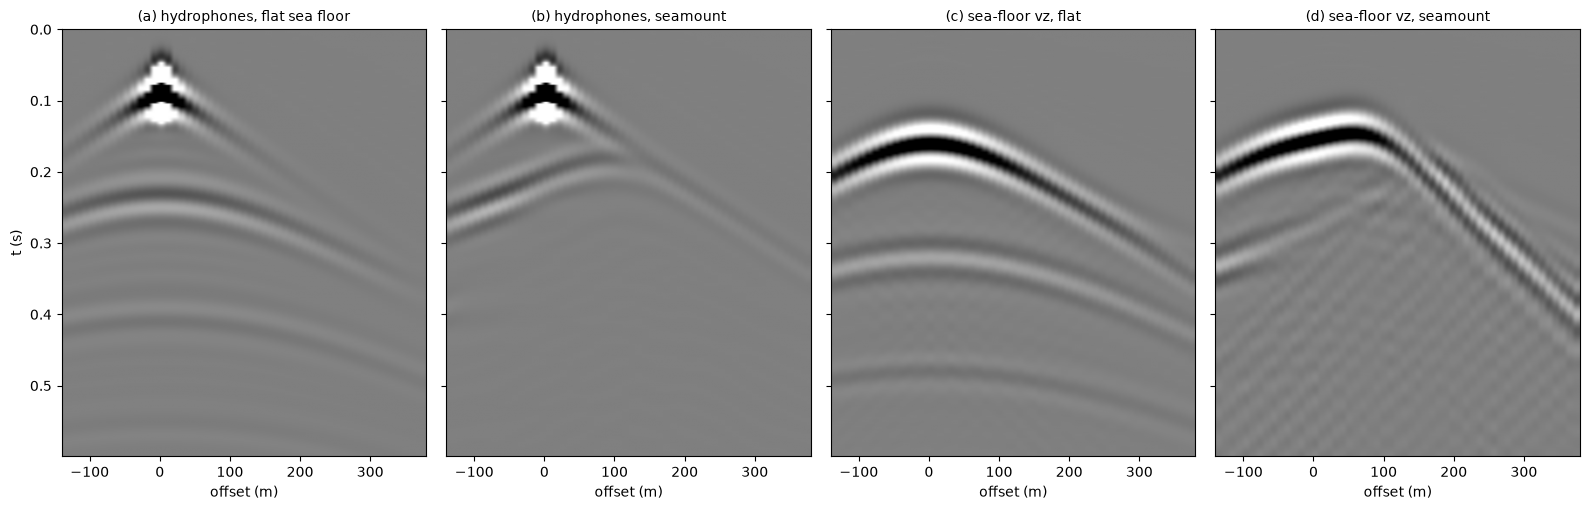

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5.2), sharey=True)
off = (rx - src[0, 0]) * DH
panels = ((hyd_flat, "(a) hydrophones, flat sea floor"), (hyd_sea, "(b) hydrophones, seamount"),
          (obs_flat, "(c) sea-floor vz, flat"), (obs_sea, "(d) sea-floor vz, seamount"))
for a_, (data, lab) in zip(ax, panels):
    ref = hyd_flat if "hydrophones" in lab else obs_flat
    clip = np.percentile(np.abs(ref), 99)
    a_.imshow(data, aspect="auto", cmap="gray", vmin=-clip, vmax=clip,
              extent=[off[0], off[-1], t[-1], t[0]])
    a_.set_title(lab, fontsize=10)
    a_.set_xlabel("offset (m)")
ax[0].set_ylabel("t (s)")
fig.tight_layout()
plt.show()

Over the flat sea floor (a, c) the records are the direct wave, the sea-floor reflection
and its multiples between the sea surface and the floor. Over the seamount (b) the reflection
comes earlier toward positive offsets, where the floor is shallower, and the multiples lose
their coherence, since the seamount's slopes send the energy out of the line. On the sea floor
(c, d) the geophones record the wave arriving through the water and, behind it, the waves that
travel in and along the rock; over the seamount (d) the first arrival comes earlier where the
geophones sit on its top, and a slower wave train crosses the line in both directions, the
waves running along the sea floor that the seamount scatters.

---

<p><strong>Download this notebook</strong> &mdash; <a href="61_sem_seafloor3d.ipynb" download><code>61_sem_seafloor3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/61_sem_seafloor3d.ipynb">view on GitHub</a></p>